In [29]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [30]:
# Load the dataset

data = pd.read_csv('advertising.csv')

In [31]:
data

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [32]:
# Check for missing values

print(data.isnull().sum())

TV           0
radio        0
newspaper    0
sales        0
dtype: int64


In [33]:
# Define features (X) and target variable (y)

X = data[['TV', 'radio', 'newspaper']]
y = data['sales']

In [34]:
X

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4
...,...,...,...
195,38.2,3.7,13.8
196,94.2,4.9,8.1
197,177.0,9.3,6.4
198,283.6,42.0,66.2


In [35]:
y

0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: sales, Length: 200, dtype: float64

In [36]:
from sklearn.model_selection import train_test_split

# Split first
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42)


In [37]:


# THEN scale
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)   
X_test = scaler.transform(X_test)         

In [38]:

from sklearn.linear_model import LinearRegression
# Initialize the Linear Regression model

model = LinearRegression()

In [39]:
# Train the model

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [40]:
# Make predictions on the test set

y_pred = model.predict(X_test)

In [41]:

from sklearn.metrics import mean_squared_error, r2_score

# Calculate Mean Squared Error (MSE) and R-squared (R2) score
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print(f'Root Mean Squared Error: {rmse}')
print(f'R-squared: {r2}')


Root Mean Squared Error: 1.9485372043446385
R-squared: 0.8609466508230368


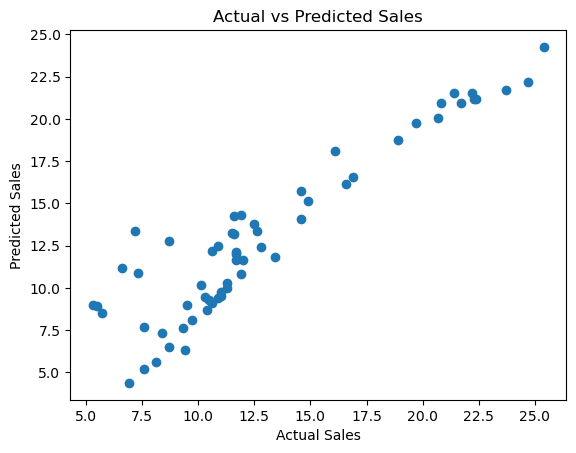

Coefficients: [3.68334078 2.90625242 0.14194772]
Intercept: 14.497142857142858


In [42]:
# Visualize the predictions vs actual values
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()

# Print the coefficients
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)

In [43]:

from sklearn.linear_model import Lasso

lasso = Lasso(alpha= 0.01)  

lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)
y_pred_lasso


array([16.55282732, 21.16450164, 21.52908111, 10.89379391, 22.19290913,
       13.35128952, 21.18175877,  7.37203797, 13.28377874, 15.12251998,
        9.03788902,  6.54524531, 14.28348545,  8.99156451,  9.47013806,
       12.00872014,  8.92603794, 16.15749668, 10.30564532, 18.72076983,
       19.74036314, 13.74863886, 12.50827464, 21.50347835,  7.63556051,
        5.63679649, 20.90086938, 11.81964132,  9.09561209,  8.53896176,
       12.18436517,  9.98465253, 21.70264428, 12.7627383 , 18.08949574,
       20.07068028, 14.27081942, 20.91225465, 10.85682877,  4.41005496,
        9.5278916 , 12.41783308, 10.17991545,  8.11076152, 13.17159475,
        5.252781  ,  9.29834751, 14.09818397,  8.70299942, 11.67338778,
       15.71478374, 11.64425291, 13.34223197, 11.15527198,  6.36155094,
        9.77267683,  9.43813412, 24.22408894,  7.71682376, 12.16676195])

In [44]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=0.01) 

ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)
y_pred_ridge


array([16.56533435, 21.18783154, 21.55063415, 10.88952668, 22.20165643,
       13.35572089, 21.19643102,  7.35073926, 13.27550945, 15.12445769,
        9.01469136,  6.52599019, 14.30231184,  8.97054669,  9.45714978,
       12.00475096,  8.9159126 , 16.15601541, 10.29612734, 18.72436561,
       19.76802109, 13.77505417, 12.49643237, 21.53468753,  7.60897741,
        5.61257594, 20.91714703, 11.8063909 ,  9.08113176,  8.51441186,
       12.17619551,  9.96945834, 21.72968226, 12.77803206, 18.10092767,
       20.07541528, 14.26192704, 20.93793519, 10.83954927,  4.38258354,
        9.51365375, 12.40492781, 10.17076408,  8.09121558, 13.16394161,
        5.22494545,  9.28934341, 14.09328946,  8.69067782, 11.66132927,
       15.71838941, 11.63171384, 13.35383128, 11.15343668,  6.33689023,
        9.76192706,  9.41985615, 24.25455958,  7.69560627, 12.15326236])

In [45]:

def evaluate(model_name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name} Results:")
    print(f"  RMSE: {rmse:.3f}")
    print(f"  R²:   {r2:.3f}\n")

evaluate("Linear Regression", y_test, y_pred)
evaluate("Lasso Regression", y_test, y_pred_lasso)
evaluate("Ridge Regression", y_test, y_pred_ridge)


Linear Regression Results:
  RMSE: 1.949
  R²:   0.861

Lasso Regression Results:
  RMSE: 1.945
  R²:   0.861

Ridge Regression Results:
  RMSE: 1.949
  R²:   0.861



In [46]:
# Print coefficients

print("Lasso Coefficients:", lasso.coef_)

print("Ridge Coefficients:", ridge.coef_)

Lasso Coefficients: [3.67403297 2.8993835  0.13460248]
Ridge Coefficients: [3.68308954 2.90603688 0.14201952]


In [47]:
import numpy as np
from sklearn.linear_model import LassoCV, RidgeCV

alphas = np.linspace(0.01, 10, 100)  

In [48]:
alphas

array([ 0.01      ,  0.11090909,  0.21181818,  0.31272727,  0.41363636,
        0.51454545,  0.61545455,  0.71636364,  0.81727273,  0.91818182,
        1.01909091,  1.12      ,  1.22090909,  1.32181818,  1.42272727,
        1.52363636,  1.62454545,  1.72545455,  1.82636364,  1.92727273,
        2.02818182,  2.12909091,  2.23      ,  2.33090909,  2.43181818,
        2.53272727,  2.63363636,  2.73454545,  2.83545455,  2.93636364,
        3.03727273,  3.13818182,  3.23909091,  3.34      ,  3.44090909,
        3.54181818,  3.64272727,  3.74363636,  3.84454545,  3.94545455,
        4.04636364,  4.14727273,  4.24818182,  4.34909091,  4.45      ,
        4.55090909,  4.65181818,  4.75272727,  4.85363636,  4.95454545,
        5.05545455,  5.15636364,  5.25727273,  5.35818182,  5.45909091,
        5.56      ,  5.66090909,  5.76181818,  5.86272727,  5.96363636,
        6.06454545,  6.16545455,  6.26636364,  6.36727273,  6.46818182,
        6.56909091,  6.67      ,  6.77090909,  6.87181818,  6.97

In [49]:
# Lasso with Cross-Validation

lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)

lasso_cv.fit(X_train, y_train)


,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"n_alphas n_alphas: int, default=100Number of alphas along the regularization path... deprecated:: 1.7 `n_alphas` was deprecated in 1.7 and will be removed in 1.9. Use `alphas` instead.",'deprecated'
,"alphas alphas: array-like or int, default=NoneValues of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`... deprecated:: 1.7 `alphas=None` was deprecated in 1.7 and will be removed in 1.9, at which point the default value will be set to 100.",array([ 0.01 ... 10. ])
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [50]:
# Ridge with Cross-Validation

ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train, y_train)


,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.",array([ 0.01 ... 10. ])
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error ` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination ` (:math:`R^2`) otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.",5
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : use 'svd' if n_samples > n_features, otherwise use 'eigen' 'svd' : force use of singular value decomposition of X when X is dense, eigenvalue decomposition of X^T.X when X is sparse. 'eigen' : force computation via eigendecomposition of X.X^TThe 'auto' mode is the default and is intended to pick the cheaperoption of the two depending on the shape of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets... versionadded:: 0.24",False


In [51]:

print("Best alpha for Lasso:", lasso_cv.alpha_)
print("Best alpha for Ridge:", ridge_cv.alpha_)


Best alpha for Lasso: 0.01
Best alpha for Ridge: 0.01


In [52]:

from sklearn.metrics import mean_squared_error, r2_score

def evaluate(model_name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name} | RMSE: {rmse:.3f} | R²: {r2:.3f}")
    

In [53]:
# Predictions

y_pred_lasso = lasso_cv.predict(X_test)
y_pred_ridge = ridge_cv.predict(X_test)


In [54]:
# Evaluate

evaluate("LassoCV (α tuned)", y_test, y_pred_lasso)
evaluate("RidgeCV (α tuned)", y_test, y_pred_ridge)


LassoCV (α tuned) | RMSE: 1.945 | R²: 0.861
RidgeCV (α tuned) | RMSE: 1.949 | R²: 0.861


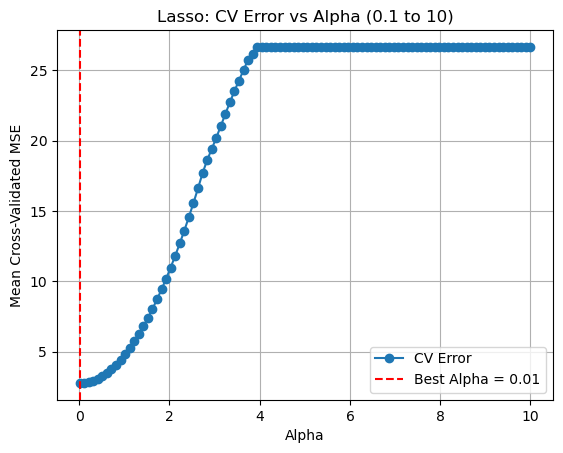

In [55]:
import matplotlib.pyplot as plt

plt.plot(lasso_cv.alphas_, np.mean(lasso_cv.mse_path_, axis=1), marker='o', label='CV Error')
plt.axvline(lasso_cv.alpha_, color='red', linestyle='--', label=f'Best Alpha = {lasso_cv.alpha_:.2f}')
plt.xlabel("Alpha")
plt.ylabel("Mean Cross-Validated MSE")
plt.title("Lasso: CV Error vs Alpha (0.1 to 10)")
plt.legend()
plt.grid(True)
plt.show()


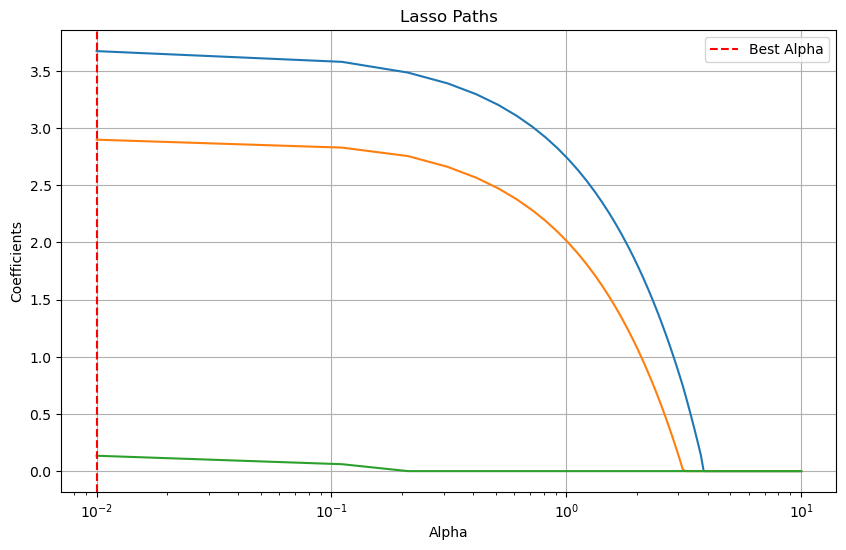

In [56]:
from sklearn.linear_model import lasso_path

alphas_lasso, coefs_lasso, _ = lasso_path(X_train, y_train, alphas=alphas)

plt.figure(figsize=(10,6))

for coef in coefs_lasso:
    plt.plot(alphas_lasso, coef)

plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Coefficients')
plt.title('Lasso Paths')
plt.axvline(lasso_cv.alpha_, color='red', linestyle='--', label='Best Alpha')
plt.legend()
plt.grid(True)
plt.show()
